# setup + imports

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import json

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [10]:
train_data = pd.read_csv('training_set.csv')

In [11]:
known = train_data.loc[train_data['label']!=0]
print(known.head())
print(len(known))

      SampleID   feature1  feature2  feature3  feature4  feature5  label
46   TRAIN_047  -0.533875  4.896798  0.657973  1.269258  3.626639     -1
141  TRAIN_142   3.188243 -2.940096 -0.403756  0.737487  3.842465      1
182  TRAIN_183  12.170832  6.432842 -0.030263  0.467199  3.884141      1
379  TRAIN_380  -3.223877  1.471688  0.042571  1.215378  3.800927     -1
4


In [18]:
X = train_data[['feature1', 'feature2', 'feature3', 'feature4', 'feature5']]
y = train_data['label']

# data exploration

In [15]:
scaler = StandardScaler()
scaler.fit(X)
X_scaled = pd.DataFrame(scaler.transform(X), columns=X.columns, index=X.index)
X_scaled

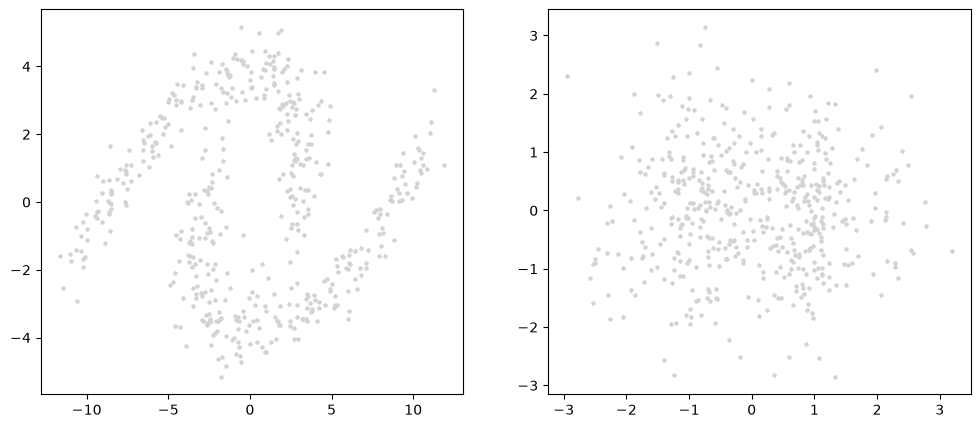

In [26]:
P = PCA(n_components=2).fit_transform(X)
P_scaled = PCA(n_components=2).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(P[:, 0], P[:, 1], c='lightgray', s=5)
axes[1].scatter(P_scaled[:, 0], P_scaled[:, 1], c='lightgray', s=5)
plt.show()

feature1 4.949
feature2 2.831
feature3 0.298
feature4 0.313
feature5 0.303


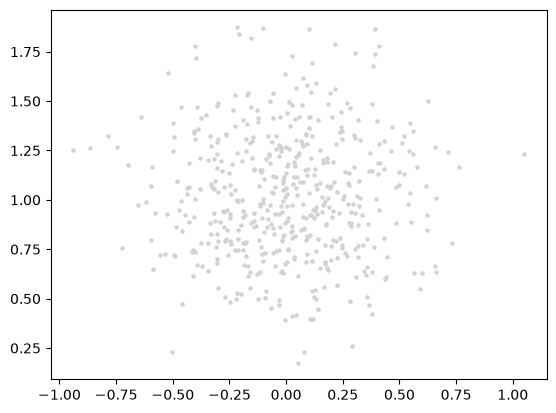

In [30]:
for c in X.columns:
    print(c, round(X[c].std(), 3))
plt.scatter(X['feature3'], X['feature4'], c='lightgray', s=5)

# models

In [45]:
from sklearn.cluster import DBSCAN
labels = DBSCAN(eps=1.1, min_samples=5).fit_predict(X)
print(np.unique(labels, return_counts=True))  

(array([-1,  0,  1]), array([  7, 249, 244]))


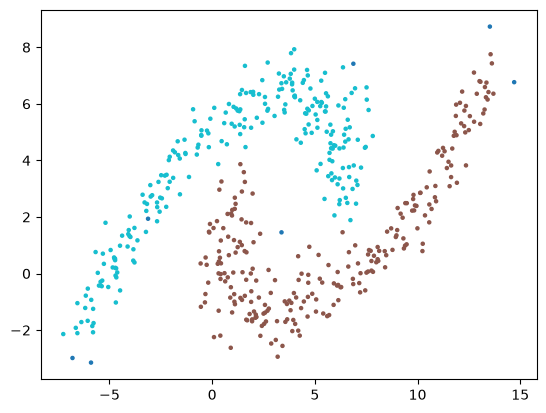

In [46]:
plt.scatter(X['feature1'], X['feature2'], c=labels, s=5, cmap='tab10')
plt.show()

In [52]:
pts = X[['feature1', 'feature2']].values
fixed = labels.copy()
for i in range(len(pts)):
    if labels[i] == -1:
        best = None
        best_d = None
        for j in range(len(pts)):
            if labels[j] != -1:
                d = ((pts[i] - pts[j]) ** 2).sum()
                if best_d is None or d < best_d:
                    best_d = d
                    best = j
        fixed[i] = labels[best]

labels = fixed

# submission

(array([-1,  0,  1]), array([ 47, 728, 725]))


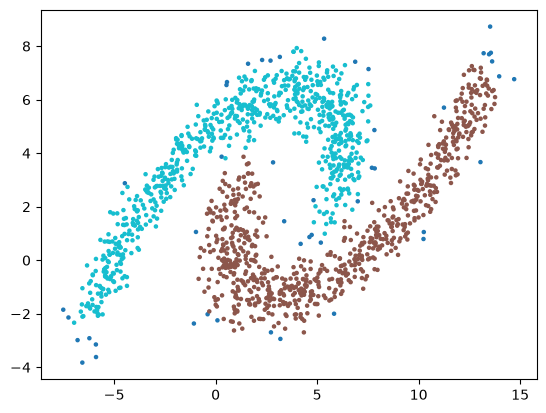

In [66]:
cols = ['feature1', 'feature2']          # the same columns you used on train
val = pd.read_csv('validation_set.csv')
test = pd.read_csv('test_set.csv')

# 1. all points together, train first so known.index still points to the right rows
X_all = pd.concat([train_data[cols], val[cols], test[cols]], ignore_index=True)
labels = DBSCAN(eps=0.5, min_samples=5).fit_predict(X_all)
print(np.unique(labels, return_counts=True))
plt.scatter(X_all['feature1'], X_all['feature2'], c=labels, s=5, cmap='tab10')
plt.show()

In [67]:
# 2. noise fix, only needed if -1 appears in the counts above
pts = X_all.values
for i in range(len(pts)):
    if labels[i] == -1:
        best = None
        best_d = None
        for j in range(len(pts)):
            if labels[j] != -1:
                d = ((pts[i] - pts[j]) ** 2).sum()
                if best_d is None or d < best_d:
                    best_d = d
                    best = j
        labels[i] = labels[best]

# 3. cluster -> label, using the 4 known rows
cluster_to_label = {}
for i in known.index:
    cluster_to_label[labels[i]] = known['label'][i]
print(cluster_to_label)

preds = []
for c in labels:
    preds.append(cluster_to_label[c])
preds = np.array(preds)

# 4. split back: first train, then val, then test
n_tr = len(train_data)
n_va = len(val)
pred_val = preds[n_tr:n_tr + n_va]
pred_test = preds[n_tr + n_va:]

# 5. submission
sub_a = pd.DataFrame({'SampleID': val['SampleID'], 'ClasamentType': 'A', 'label': pred_val})
sub_b = pd.DataFrame({'SampleID': test['SampleID'], 'ClasamentType': 'B', 'label': pred_test})
sub = pd.concat([sub_a, sub_b], ignore_index=True)
sub.to_csv('submission.csv', index=False)
print(sub.shape)
print(sub['label'].value_counts())

{np.int64(1): np.int64(-1), np.int64(0): np.int64(1)}
(1000, 3)
label
-1    501
 1    499
Name: count, dtype: int64


In [ ]:
›